In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("hf_token", "")
os.environ["USER_AGENT"] = "agentic-rag-notebook"


In [2]:
from typing import Annotated, Literal, Sequence
from typing_extensions import TypedDict
from pydantic import BaseModel, Field

from langchain.chat_models import init_chat_model
from langchain_huggingface import HuggingFaceEmbeddings          # OpenAIEmbeddings ki jagah
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.tools import create_retriever_tool           # naya import path
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

llm = init_chat_model("groq:openai/gpt-oss-20b", temperature=0)   
embedding = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")


C:\Users\Adit Sharma\AppData\Local\Temp\ipykernel_7528\2564641084.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [3]:
def build_retriever(urls):
    docs = [d for url in urls for d in WebBaseLoader(url).load()]      # list of lists ko flat kiya
    splits = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100).split_documents(docs)
    return FAISS.from_documents(splits, embedding).as_retriever()

retriever = build_retriever([
    "https://langchain-ai.github.io/langgraph/tutorials/introduction/",
    "https://langchain-ai.github.io/langgraph/tutorials/workflows/",
    "https://langchain-ai.github.io/langgraph/how-tos/map-reduce/",
])
retriever_langchain = build_retriever([
    "https://python.langchain.com/docs/tutorials/",
    "https://python.langchain.com/docs/tutorials/chatbot/",
    "https://python.langchain.com/docs/tutorials/qa_chat_history/",
])

retriever.invoke("what is langgraph")


[Document(id='dad033cf-3aac-4690-a19a-60cda9aa8e9b', metadata={'source': 'https://langchain-ai.github.io/langgraph/tutorials/introduction/', 'title': 'Redirecting...', 'language': 'en'}, page_content='Redirecting...\n\n\n\n\n\n\nRedirecting...'),
 Document(id='af4de64d-682e-4567-a716-61c8e6302ce4', metadata={'source': 'https://langchain-ai.github.io/langgraph/tutorials/workflows/', 'title': 'Redirecting...', 'language': 'en'}, page_content='Redirecting...\n\n\n\n\n\n\nRedirecting...'),
 Document(id='82924528-7ff3-43ba-a419-3c0783d4c6e2', metadata={'source': 'https://langchain-ai.github.io/langgraph/how-tos/map-reduce/', 'title': 'Redirecting...', 'language': 'en'}, page_content='Redirecting...\n\n\n\n\n\n\nRedirecting...')]

In [4]:
retriever_tool = create_retriever_tool(
    retriever, "retriever_vector_db_blog", "Search and return information about LangGraph")
retriever_tool_langchain = create_retriever_tool(
    retriever_langchain, "retriever_vector_langchain_blog", "Search and return information about LangChain")

tools = [retriever_tool, retriever_tool_langchain]
llm_with_tools = llm.bind_tools(tools)      


In [5]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]   # add_messages = list mein append karo, replace nahi


In [6]:
def agent(state):
    print("---CALL AGENT---")
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


class Grade(BaseModel):
    """Binary score for relevance check."""
    binary_score: Literal["yes", "no"] = Field(description="Relevance score 'yes' or 'no'")

grade_prompt = PromptTemplate.from_template(
    "You are a grader assessing relevance of a retrieved document to a user question.\n"
    "Here is the retrieved document:\n\n{context}\n\n"
    "Here is the user question: {question}\n"
    "If the document contains keyword(s) or semantic meaning related to the question, grade it as relevant.\n"
    "Give a binary score 'yes' or 'no'."
)
grader = grade_prompt | llm.with_structured_output(Grade)

def grade_documents(state) -> Literal["generate", "rewrite"]:
    print("---CHECK RELEVANCE---")
    question = state["messages"][0].content      # user ka original sawaal
    docs = state["messages"][-1].content         # ToolMessage, yaani retriever ka output
    score = grader.invoke({"question": question, "context": docs}).binary_score
    if score == "yes":
        print("---DECISION: DOCS RELEVANT---")
        return "generate"
    print("---DECISION: DOCS NOT RELEVANT---")
    return "rewrite"

rag_prompt = ChatPromptTemplate.from_template(
    "You are an assistant for question-answering tasks. Use the following pieces of retrieved context "
    "to answer the question. If you don't know the answer, just say that you don't know. "
    "Use three sentences maximum and keep the answer concise.\n"
    "Question: {question}\nContext: {context}\nAnswer:"
)
rag_chain = rag_prompt | llm | StrOutputParser()

def generate(state):
    print("---GENERATE---")
    question = state["messages"][0].content
    docs = state["messages"][-1].content
    return {"messages": [rag_chain.invoke({"context": docs, "question": question})]}


def rewrite(state):
    print("---TRANSFORM QUERY---")
    question = state["messages"][0].content
    msg = [HumanMessage(content=(
        "Look at the input and try to reason about the underlying semantic intent / meaning.\n"
        f"Here is the initial question:\n-------\n{question}\n-------\n"
        "Formulate an improved question. Reply with only the question."
    ))]
    better = llm.invoke(msg).content
    return {"messages": [HumanMessage(content=better)]}   # user ki taraf se naya sawaal


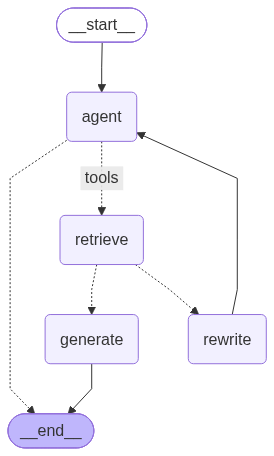

In [7]:
workflow = StateGraph(AgentState)
workflow.add_node("agent", agent)
workflow.add_node("retrieve", ToolNode(tools))
workflow.add_node("rewrite", rewrite)
workflow.add_node("generate", generate)

workflow.add_edge(START, "agent")
workflow.add_conditional_edges("agent", tools_condition, {"tools": "retrieve", END: END})
workflow.add_conditional_edges("retrieve", grade_documents)   # "generate" ya "rewrite" return karta hai
workflow.add_edge("generate", END)
workflow.add_edge("rewrite", "agent")                         # yahi loop hai

graph = workflow.compile()

from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))


In [8]:
cfg = {"recursion_limit": 15}    

for q in ["What is Langgraph?", "What is Langchain?", "What is Machine learning?"]:
    result = graph.invoke({"messages": [HumanMessage(content=q)]}, config=cfg)
    print(f"\n✅ {q}\n", result["messages"][-1].content)


---CALL AGENT---
---CHECK RELEVANCE---
---DECISION: DOCS NOT RELEVANT---
---TRANSFORM QUERY---
---CALL AGENT---

✅ What is Langgraph?
 ## What is LangGraph?

**LangGraph** is a high‑level, open‑source framework built on top of the LangChain ecosystem that lets developers design, run, and debug *state‑driven, graph‑based* applications powered by large language models (LLMs).  
It turns the idea of “a conversation” or “a workflow” into a **directed graph** where:

| Node | What it does |
|------|--------------|
| **LLM node** | Sends a prompt to an LLM and receives a text response. |
| **Tool node** | Calls an external API, database, or custom function. |
| **Decision node** | Evaluates the current state and decides which edge to follow. |
| **State node** | Holds the mutable context (memory, variables, flags). |

The graph is **explicitly defined** (you write the nodes and edges), but the framework handles the heavy lifting of:

* **Prompt engineering** – automatically injecting the cur